## 1. Cohort Analysis Methodology

### Cohort Definition
A cohort is a group of customers who signed up in the same calendar month.

### Retention Definition
A customer is considered retained if they have not experienced a non-reactivation churn event by the end of the reporting month.

### Calculation

**Cohort Retention Rate (%)**

= (Retained Accounts / Original Cohort Size) × 100

### Important Rules
- Cohorts are based on customer signup month.
- Month 0 represents the signup month.
- Only non-reactivation churn events count as churn.
- Reactivation does not reverse a previous churn event.
- Cohort sizes remain fixed throughout the analysis.
- Only available observation months are included.

In [1]:

# Import required libraries
import pandas as pd

# Load cohort retention results
df = pd.read_csv("cohort_retention_output.csv")

# Display dataset dimensions
print("Total rows and columns:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display first 5 records
print("\nFirst 5 records:")
display(df.head())


Total rows and columns: (234, 6)

Column names:
['signup_cohort', 'cohort_age_month', 'reporting_month', 'cohort_size', 'retained_accounts', 'retention_rate_pct']

First 5 records:


,signup_cohort,cohort_age_month,reporting_month,cohort_size,retained_accounts,retention_rate_pct
0,2023-01,0,2023-01,17,16,94.12
1,2023-01,1,2023-02,17,16,94.12
2,2023-01,2,2023-03,17,16,94.12
3,2023-01,3,2023-04,17,15,88.24
4,2023-01,4,2023-05,17,13,76.47


In [4]:

# Check missing values
print("Missing values:")
display(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check number of unique cohorts
print("\nUnique cohorts:", df["signup_cohort"].nunique())

# Check total original cohort size
cohort_sizes = df.groupby("signup_cohort")["cohort_size"].first()

print("\nTotal accounts across cohorts:", cohort_sizes.sum())

# Check retention percentages
print("\nRetention percentage range:")
print(df["retention_rate_pct"].min(),
      "to",
      df["retention_rate_pct"].max())


Missing values:


signup_cohort         0
cohort_age_month      0
reporting_month       0
cohort_size           0
retained_accounts     0
retention_rate_pct    0
dtype: int64


Duplicate rows: 0

Unique cohorts: 24

Total accounts across cohorts: 500

Retention percentage range:
16.0 to 100.0


In [5]:
# Create monthly cohort retention table
retention_table = df.pivot(
    index="signup_cohort",
    columns="cohort_age_month",
    values="retention_rate_pct"
)

# Rename columns for readability
retention_table.columns = [
    f"Month {month}" for month in retention_table.columns
]

# Display the table
display(retention_table.round(2))

,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,Month 11,Month 12
signup_cohort,,,,,,,,,,,,,
2023-01,94.12,94.12,94.12,88.24,76.47,76.47,70.59,70.59,64.71,58.82,52.94,41.18,41.18
2023-02,100.00,88.89,83.33,83.33,77.78,77.78,77.78,77.78,77.78,61.11,61.11,61.11,61.11
2023-03,85.00,85.00,85.00,70.00,65.00,50.00,45.00,45.00,45.00,40.00,30.00,30.00,30.00
2023-04,93.33,93.33,86.67,80.00,80.00,80.00,80.00,80.00,80.00,80.00,80.00,80.00,80.00
2023-05,100.00,100.00,100.00,88.46,88.46,84.62,76.92,76.92,73.08,73.08,69.23,65.38,65.38
2023-06,100.00,92.31,92.31,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,76.92,76.92
2023-07,92.86,92.86,92.86,85.71,85.71,85.71,78.57,71.43,71.43,64.29,64.29,64.29,57.14
2023-08,100.00,93.75,93.75,93.75,81.25,75.00,75.00,68.75,62.50,62.50,56.25,43.75,43.75
2023-09,100.00,91.30,78.26,69.57,60.87,60.87,52.17,47.83,47.83,43.48,43.48,30.43,21.74


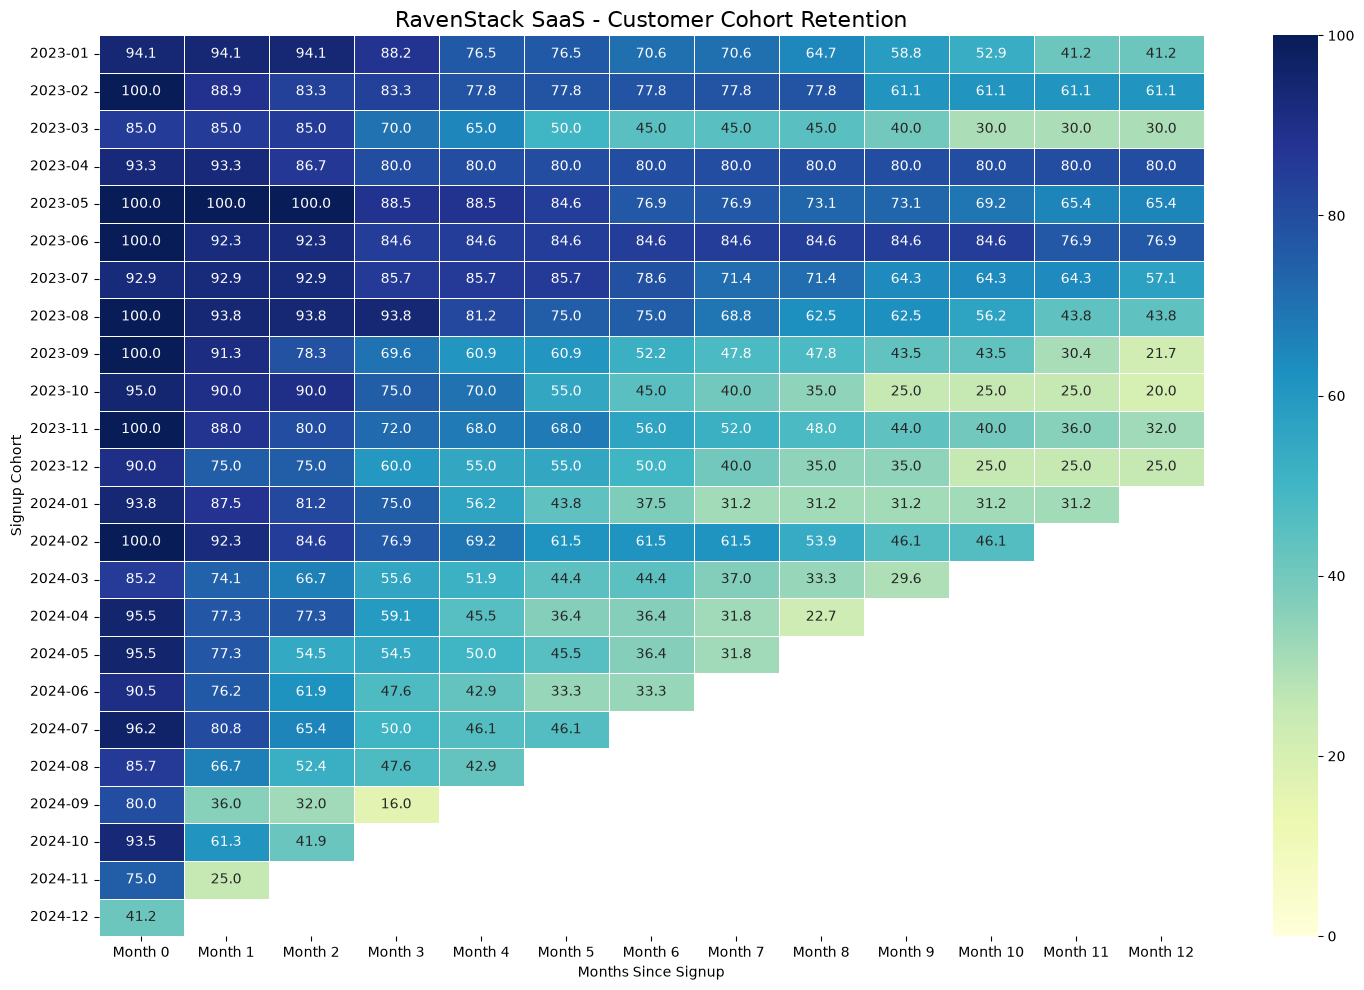

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create retention heatmap
plt.figure(figsize=(15, 10))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    mask=retention_table.isna()
)

plt.title(
    "RavenStack SaaS - Customer Cohort Retention",
    fontsize=16
)

plt.xlabel("Months Since Signup")
plt.ylabel("Signup Cohort")

plt.tight_layout()

# Display heatmap
plt.show()

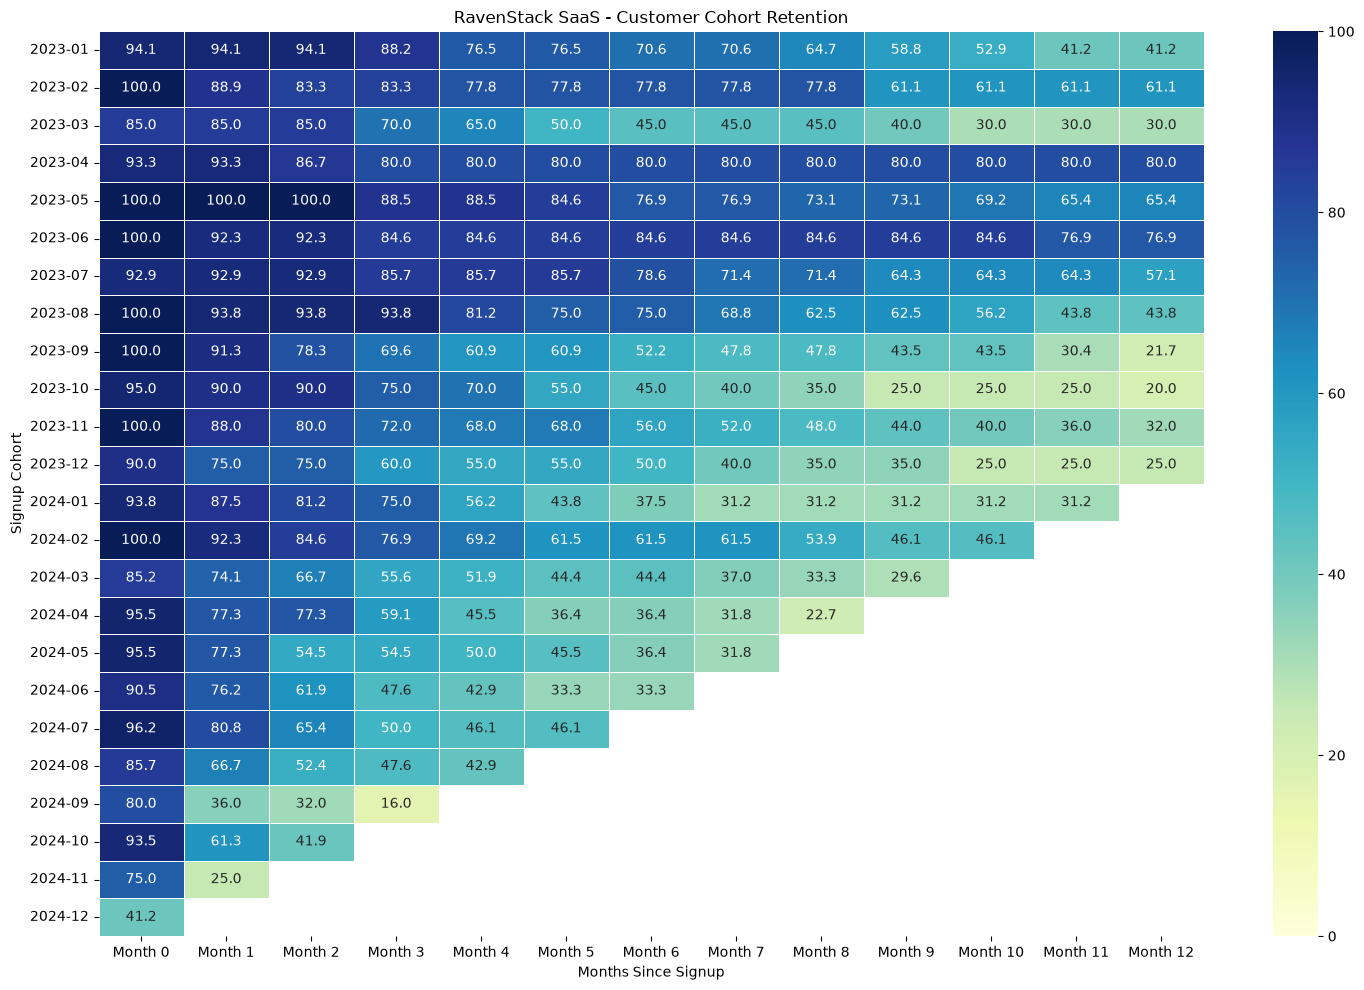

In [7]:
import os

os.makedirs("../outputs", exist_ok=True)

plt.figure(figsize=(15, 10))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    mask=retention_table.isna()
)

plt.title("RavenStack SaaS - Customer Cohort Retention")
plt.xlabel("Months Since Signup")
plt.ylabel("Signup Cohort")
plt.tight_layout()

plt.savefig(
    "../outputs/cohort_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# 1. Check retained accounts never exceed cohort size
check_1 = (df["retained_accounts"] <= df["cohort_size"]).all()

# 2. Verify retention percentages
calculated_rate = (
    df["retained_accounts"] / df["cohort_size"] * 100
)

check_2 = (
    (calculated_rate - df["retention_rate_pct"]).abs() < 0.01
).all()

# 3. Check cohort sizes remain consistent
check_3 = (
    df.groupby("signup_cohort")["cohort_size"].nunique().max() == 1
)

# 4. Check retention does not increase over cohort age
check_4 = all(
    group.sort_values("cohort_age_month")["retained_accounts"]
    .is_monotonic_decreasing
    for _, group in df.groupby("signup_cohort")
)

print("Retained accounts within cohort size:", check_1)
print("Retention percentages are correct:", check_2)
print("Cohort sizes are consistent:", check_3)
print("Retention is non-increasing:", check_4)

Retained accounts within cohort size: True
Retention percentages are correct: True
Cohort sizes are consistent: True
Retention is non-increasing: True


In [9]:
# Overall Month 0 retention
month_0 = df[df["cohort_age_month"] == 0]

month_0_retention = (
    month_0["retained_accounts"].sum()
    / month_0["cohort_size"].sum()
) * 100

# Month 12 retention for mature cohorts
month_12 = df[df["cohort_age_month"] == 12]

month_12_retention = (
    month_12["retained_accounts"].sum()
    / month_12["cohort_size"].sum()
) * 100

print(f"Overall Month 0 retention: {month_0_retention:.2f}%")
print(f"Month 12 retention (mature cohorts): {month_12_retention:.2f}%")
print("Number of cohorts with Month 12 data:", len(month_12))
print("Accounts in mature cohorts:", month_12["cohort_size"].sum())

Overall Month 0 retention: 90.60%
Month 12 retention (mature cohorts): 44.05%
Number of cohorts with Month 12 data: 12
Accounts in mature cohorts: 227


## Business Insights and Conclusions

### 1. Initial Retention
Overall Month 0 retention is **90.60%**, representing 453 retained accounts out of 500 accounts across all signup cohorts.

### 2. Long-Term Retention
Month 12 retention is **44.05%**, representing 100 retained accounts out of 227 accounts across the 12 mature cohorts.

### 3. Retention Trend
The cohort retention table and heatmap show how customer retention changes as accounts age. Retention generally declines over time, although the rate of decline differs across signup cohorts.

### 4. Cohort Maturity
The 2023 signup cohorts have up to 12 months of observation data. The 2024 cohorts have fewer observed months because they joined more recently.

### 5. Areas for Investigation
Some cohorts show comparatively sharp retention declines. These cohorts should be investigated further alongside churn reasons, subscription activity, and customer feature usage.

### Conclusion
The cohort analysis provides a month-by-month view of customer retention across 24 signup cohorts. The results establish an initial retention baseline of 90.60% and a Month 12 retention benchmark of 44.05% for mature cohorts. These findings can help RavenStack identify customer lifecycle patterns and prioritize retention improvement efforts.